# 02.P · Mini-project: predict customer spend (solution)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/02-regression/project/solution.ipynb)

Brief and rubric: [README.md](README.md). Features from before 1 Sep 2011; target = spend 1 Sep – 30 Nov 2011.

## 1. Build the customer table

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
print(raw.shape)
raw.head()


def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df.copy()
    out = out[~out["Invoice"].astype(str).str.startswith("C")]   # drop cancellations
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)]         # drop returns / free items
    out = out.dropna(subset=["Customer ID"])                       # drop guest checkouts
    out = out.drop_duplicates()
    out["Customer ID"] = out["Customer ID"].astype(int)
    out["Revenue"] = out["Quantity"] * out["Price"]
    return out

sales = clean_retail(raw)
print(f"{len(raw):,} rows → {len(sales):,} after cleaning")


cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(
    orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
    products=("StockCode", "nunique"), items=("Quantity", "sum"),
    first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"),
    country=("Country", "first"))
cust["avg_order"] = cust["spend"] / cust["orders"]
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
cust["spend_next_quarter"] = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust = cust.drop(columns=["first_order", "last_order"])
print(f"{len(cust):,} customers; features from before {cutoff.date()}, target = spend Sep–Nov 2011")
cust.head()

(541910, 8)
541,910 rows → 392,693 after cleaning
3,317 customers; features from before 2011-09-01, target = spend Sep–Nov 2011


,orders,spend,products,items,country,avg_order,tenure_days,days_since_last,spend_next_quarter
Customer ID,,,,,,,,,
12346,1,77183.60,1,74215,United Kingdom,77183.600000,225,225,0.00
12347,5,2790.86,82,1590,Iceland,558.172000,267,29,1294.32
12348,3,1487.24,22,2124,Finland,495.746667,258,148,310.00
12350,1,334.40,17,197,Norway,334.400000,210,210,0.00
12352,5,1561.81,26,254,Norway,312.362000,196,162,944.23


In [2]:
y_all = cust["spend_next_quarter"]
print(f"{len(cust):,} customers; {(y_all == 0).mean():.0%} spent nothing in the target window")
print(y_all.describe().round(0))

3,317 customers; 44% spent nothing in the target window
count      3317.0
mean        776.0
std        3927.0
min           0.0
25%           0.0
50%         171.0
75%         688.0
max      117635.0
Name: spend_next_quarter, dtype: float64


About 44% of customers did not come back at all, and the top customer spent over £100,000. Any regression on this target is fighting a wall of zeros on one side and a handful of wholesalers on the other. Module 03 will model "comes back at all" separately; here we do what Module 02 allows.

## 2. Hold out the test set

In [3]:
from sklearn.model_selection import train_test_split
feats = ["orders", "spend", "products", "avg_order", "tenure_days", "days_since_last"]
X_tr, X_te, y_tr, y_te = train_test_split(cust[feats], y_all, test_size=0.2, random_state=42)
print(len(X_tr), "train customers,", len(X_te), "test customers")

2653 train customers, 664 test customers


## 3. Baselines

In [4]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<28} MAE £{mae:8.1f}   RMSE £{rmse:8.1f}   R² {r2:6.3f}")

results = {}
def score(name, pred):
    results[name] = {"MAE": mean_absolute_error(y_te, pred), "RMSE": np.sqrt(mean_squared_error(y_te, pred)), "R²": r2_score(y_te, pred)}
    report(name, y_te, pred)

score("baseline: mean", np.full(len(y_te), y_tr.mean()))
score("baseline: median", np.full(len(y_te), y_tr.median()))

baseline: mean               MAE £  1152.8   RMSE £  6399.2   R² -0.002
baseline: median             MAE £   995.2   RMSE £  6448.1   R² -0.018


## 4. One feature

In [5]:
from sklearn.linear_model import LinearRegression
line = LinearRegression().fit(X_tr[["spend"]], y_tr)
print(f"spend_next ≈ {line.coef_[0]:.2f} × past_spend + {line.intercept_:.0f}")
score("line on spend", line.predict(X_te[["spend"]]))

spend_next ≈ 0.48 × past_spend + 6
line on spend                MAE £   777.1   RMSE £  3938.2   R²  0.620


Beats both baselines on all three metrics. One column, two numbers, and a third of the mean-baseline error gone.

## 5. All six features

In [6]:
multi = LinearRegression().fit(X_tr, y_tr)
print(pd.Series(multi.coef_, index=feats).round(3))
score("six features (linear)", multi.predict(X_te))

orders             15.534
spend               0.490
products            3.957
avg_order          -0.763
tenure_days        -3.212
days_since_last     1.923
dtype: float64
six features (linear)        MAE £   769.8   RMSE £  3779.0   R²  0.651


- `spend` ≈ 0.5: holding everything else fixed, each past pound predicts about 50p next quarter. The dominant term.
- `days_since_last` is **positive**, which looks wrong (longer silence, more spend?). It is the "holding others fixed" effect from 02.5: among customers with the same past spend and order count, the ones with long gaps are the big infrequent wholesale buyers. Alone, recency correlates *negatively* with future spend. The coefficient describes the model, not the customer.
- `orders` is negative for the same reason: with spend fixed, more orders means smaller orders, which means a smaller customer.

## 6. A curve

In [7]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
poly2 = make_pipeline(StandardScaler(), PolynomialFeatures(2), LinearRegression()).fit(X_tr[["spend"]], y_tr)
score("poly degree 2 on spend", poly2.predict(X_te[["spend"]]))

poly degree 2 on spend       MAE £   773.1   RMSE £  3878.9   R²  0.632


## 7. Trees

In [8]:
from sklearn.tree import DecisionTreeRegressor
rows = []
for depth in [2, 4, 8, None]:
    t = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(X_tr, y_tr)
    score(f"tree depth={depth}", t.predict(X_te))
    rows.append({"depth": str(depth), "leaves": t.get_n_leaves(),
                 "train R²": r2_score(y_tr, t.predict(X_tr)), "test R²": r2_score(y_te, t.predict(X_te))})
pd.DataFrame(rows).round(3)

tree depth=2                 MAE £   952.4   RMSE £  4864.4   R²  0.421
tree depth=4                 MAE £   863.3   RMSE £  4715.4   R²  0.456
tree depth=8                 MAE £   800.7   RMSE £  4911.0   R²  0.410
tree depth=None              MAE £   921.6   RMSE £  4755.4   R²  0.447


,depth,leaves,train R²,test R²
0,2,4,0.705,0.421
1,4,13,0.791,0.456
2,8,66,0.970,0.410
3,None,1861,1.000,0.447


Train R² rises with depth to 1.0; test R² does not follow. Beyond a shallow depth the tree is memorising the training customers, and even at its best it trails the linear models: the leaf-mean mechanism cannot follow a target that keeps growing with past spend.

## 8. Leaderboard

In [9]:
board = pd.DataFrame(results).T.sort_values("MAE")
board.round({"MAE": 1, "RMSE": 1, "R²": 3})

,MAE,RMSE,R²
six features (linear),769.8,3779.0,0.651
poly degree 2 on spend,773.1,3878.9,0.632
line on spend,777.1,3938.2,0.620
tree depth=8,800.7,4911.0,0.410
tree depth=4,863.3,4715.4,0.456
tree depth=None,921.6,4755.4,0.447
tree depth=2,952.4,4864.4,0.421
baseline: median,995.2,6448.1,-0.018
baseline: mean,1152.8,6399.2,-0.002


**Which metric for marketing?** They are choosing 2,000 customers out of thousands by *rank*; what matters is whether big spenders land near the top, not the exact pounds. RMSE and R² weight the big customers heavily, so they are the better guide here; MAE describes the typical customer, who will not get a catalogue anyway. Report MAE for honesty about typical error, choose by R².

## 9. Residuals of the winner

best by R²: six features (linear)


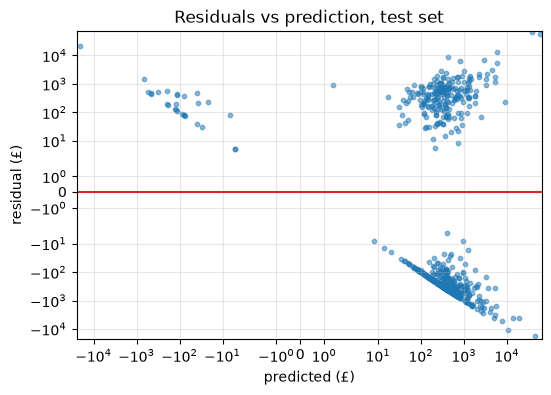

,orders,spend,products,avg_order,tenure_days,days_since_last,spend_next_quarter,predicted
Customer ID,,,,,,,,
17450,22,85610.0,107,3891.0,267,8,107218.0,39300.0
18102,26,130537.0,54,5021.0,267,26,117635.0,60331.0
12346,1,77184.0,1,77184.0,225,225,0.0,-20930.0


In [10]:
import matplotlib.pyplot as plt
best_name = board.index[board["R²"].argmax()]
print("best by R²:", best_name)
best = LinearRegression().fit(X_tr, y_tr)                     # the six-feature linear model
pred_te = best.predict(X_te)
resid = y_te - pred_te

plt.figure(figsize=(6, 4))
plt.scatter(pred_te, resid, s=10, alpha=.5); plt.axhline(0, color="tab:red")
plt.xscale("symlog"); plt.yscale("symlog")
plt.xlabel("predicted (£)"); plt.ylabel("residual (£)"); plt.title("Residuals vs prediction, test set"); plt.grid(alpha=.3)
plt.show()

worst = resid.abs().sort_values(ascending=False).head(3).index
cust.loc[worst, feats + ["spend_next_quarter"]].assign(predicted=best.predict(cust.loc[worst, feats]).round(0)).round(0)

The three biggest misses are wholesalers: customers with very large past spend whose next quarter was either far above or far below the line. One of them can move RMSE by hundreds of pounds on its own. There is no fix for that inside Module 02; Module 04 discusses outlier handling and Module 05 brings models that cope better.

## 10. The ranked list

In [11]:
cust["predicted"] = best.predict(cust[feats])
top20 = cust.sort_values("predicted", ascending=False).head(20)[["orders", "spend", "days_since_last", "predicted", "spend_next_quarter"]].round(0)
top20["in_test_set"] = top20.index.isin(X_te.index)
print(f"{top20['in_test_set'].sum()} of the top 20 are test customers")
top20

5 of the top 20 are test customers


,orders,spend,days_since_last,predicted,spend_next_quarter,in_test_set
Customer ID,,,,,,
14646,40,176356.0,5,85191.0,92122.0,False
18102,26,130537.0,26,60331.0,117635.0,True
12415,13,99146.0,13,44115.0,25768.0,True
14156,35,84977.0,14,42242.0,32233.0,False
14911,106,74381.0,5,41798.0,62351.0,False
17450,22,85610.0,8,39300.0,107218.0,True
17511,20,56175.0,14,26588.0,27508.0,False
16029,46,52213.0,7,25143.0,28638.0,False
15311,63,44997.0,12,23877.0,14461.0,False


Most of the top 20 were in the training set, so their `spend_next_quarter` column is not an independent check: the model saw those numbers. Only the test rows are honest evidence of ranking quality, and there are few of them at the very top. A proper answer needs cross-validation (04.7) so every customer gets an out-of-sample prediction.

## 11. Recommendation to the head of marketing

> **Model:** a six-feature linear regression on past orders, spend, product range, average order, tenure and recency.
> **Accuracy:** on customers it never saw it is typically about **£770 off** per customer and explains about **two-thirds** of the variation in next-quarter spend. The obvious baseline (assume everyone spends the average) is about £1,150 off. Ranking the top 2,000 by this model will concentrate the catalogue on customers with high past spend who ordered recently.
> **Caveat:** a few dozen wholesale accounts dominate both the spend and the model's errors; their forecasts can be off by tens of thousands. Treat the top ~50 as a separate list to be checked by an account manager, not mailed automatically.
> **Next:** make the evaluation stronger with cross-validation, test whether handling the 44% of non-returners as a separate yes/no model improves the ranking (Module 03), and try models that handle the wholesalers better (Module 05).

## Stretch: the log target

In [12]:
log_model = LinearRegression().fit(X_tr, np.log1p(y_tr))
pred_log = np.expm1(log_model.predict(X_te))
print("max prediction before clipping: £{:,.0f}".format(pred_log.max()))
pred_log = np.clip(pred_log, 0, y_tr.max())               # a linear model in log space can extrapolate to absurd values
report("six features, log target (clipped)", y_te, pred_log)
report("six features, raw target", y_te, multi.predict(X_te))

max prediction before clipping: £211,938,814,826,096,416
six features, log target (clipped) MAE £  1270.7   RMSE £  7600.0   R² -0.414
six features, raw target     MAE £   769.8   RMSE £  3779.0   R²  0.651


A cautionary result. Before clipping, the log model's largest prediction is in the *quadrillions*: a straight line in log space, extrapolated to a wholesaler, becomes an exponential explosion. Even clipped, it is worse than the raw model on every metric, because squashing the target tells the model to care about everyone equally, and in this table the pounds are concentrated in exactly the customers it then ignores. Log targets are a real tool (they help when the goal is the typical customer and the features are scaled sensibly), but they are not a free upgrade. Module 04 revisits the choice with proper validation.